# 1. Interactive deconvolution: choosing the settings station by station

The rupture of an earthquake lasts a fraction of a second for a magnitude 3 event, and it looks shorter at
stations the rupture moves toward. These **apparent source time functions (ASTFs)** are recovered by removing the
path and site effects from the target record with an **empirical Green's function (EGF)**: the record of a smaller,
nearby earthquake at the same station, whose own rupture is short enough to treat as a spike. The removal is a
deconvolution; `bayes2mt` uses the **projected Landweber deconvolution (PLD)**, which keeps the ASTF positive and
non-zero only inside a chosen time window (the *support*).

This is the first step for a new event: for each station and phase, choose where the support starts and how long it
is (and, if needed, a small time shift of the EGF window), then accept or reject the station. The choices are saved
in `picks.csv`. Notebook 2 re-creates every ASTF from that file and builds the duration table; notebook 3 inverts it.

**Demo data:** the Mw 3.4 earthquake of 2020-05-03 in Haenam, South Korea, and its EGF (event 16 of Seo et al.,
2026). The picker starts from the settings used in the paper (`data/event016/picks.csv`); a station without a saved
setting starts from the defaults (`interactive.DEFAULT_PICK`: start −0.02 s, duration 0.10 s, EGF shift 0 s,
band-pass 1–100 Hz, 100 iterations, no resampling).

`PLDPicker` shows, for one station and phase at a time, everything needed to choose the deconvolution settings,
and records each choice so the ASTFs can be re-created exactly (`pld.retrieve_from_picks`):

- **sliders** for the start and the duration of the ASTF support and the EGF time shift; the figure follows the
  slider while you drag it (the number next to a slider can be typed into, and the arrow keys move one step);
- the figure: (top) the duration-misfit trade-off curve, full and zoomed, with the chosen duration circled;
  (bottom) the ASTF with its support and τc, the target and EGF windows, and the target with its reconstruction;
- a badge with the VR and τc and whether the ASTF passes the quality control (VR ≥ 70 %);
- **Accept** writes the ASTF (`<output_dir>/S/direct/<station>_pld_stf.pkl`) and the settings
  (`<output_dir>/picks.csv`) and moves to the next station; **Reject** marks the station; **Save table** writes the
  duration table of the accepted stations.

Your work is kept in `picker_output/`: running this notebook again **resumes** where you stopped (nothing is
deleted). To start over, delete or rename that folder, or set another `OUT`.

**How to use:** run the first two code cells; the interface appears under "The live interface". The section after it
shows the same steps as plain method calls on a *separate* picker, so running it does not change your session.

In [1]:
import json
import tempfile

from bayes2mt.interactive import PLDPicker
from bayes2mt.plotting import use_style

DATA = "data/event016"
event = json.load(open(f"{DATA}/event.json"))
HYPOCENTER = dict(evla=event["latitude"], evlo=event["longitude"], evdp=event["depth_km"])
OUT = "picker_output"                       # your session: kept between runs
picker = PLDPicker(DATA, "S", picks=f"{DATA}/picks.csv", output_dir=OUT, **HYPOCENTER)
print("font:", use_style())
print(repr(picker))

font: dejavu sans
PLDPicker(phase='S', stations=41, accepted=0, rejected=0, current='MUN')


## The live interface

Choose a station, move the sliders, then **Accept** or **Reject**; **Save table** writes `picker_output/tauc_table_S.csv`.

*If no interface appears* (only text such as `VBox(...)`, or an error box): the widget front end of your Jupyter
server must understand the kernel's ipywidgets version. The classic Notebook 6 front end (widgetsnbextension 3.x)
renders ipywidgets 7 only; install `ipywidgets>=7.8,<8` in this environment (as `environment.yml` does) and restart
the kernel. JupyterLab, Notebook 7 and VS Code render ipywidgets 7 and 8.

In [2]:
picker.ui

## The same steps without widgets

Every control calls a plain method: `select`, `set_params`, `accept`, `reject`, `duration_table`. The figure of the
current station is `plot()`. This demonstration uses its own picker, writing to a temporary folder.

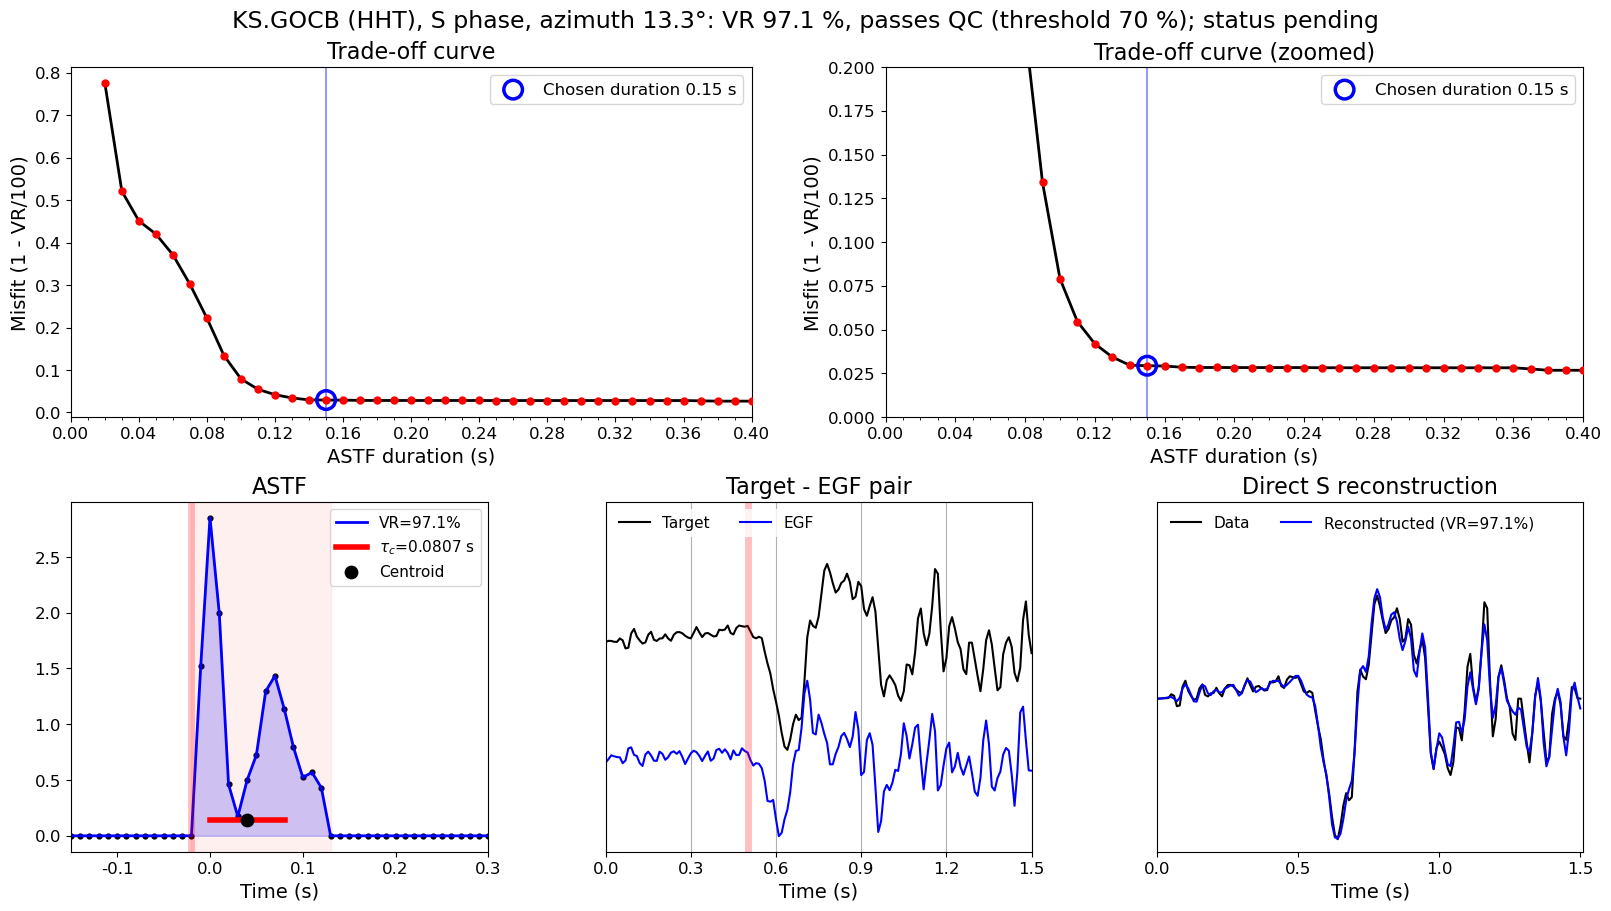

In [3]:
demo = PLDPicker(DATA, "S", picks=f"{DATA}/picks.csv", output_dir=tempfile.mkdtemp(prefix="picker_demo_"),
                 **HYPOCENTER)
demo.select("GOCB")
fig = demo.plot()

A support that is too short cuts off the end of the rupture: the misfit rises and the ASTF is truncated. The
settings in `picks.csv` (0.09 s here would be too short; the chosen 0.15 s sits at the start of the plateau):

In [4]:
demo.set_params(duration=0.09)
a_short = demo.compute()
demo.set_params(duration=0.15)
a_chosen = demo.compute()
print(f"duration 0.09 s: VR {a_short.vr:.1f} %;  duration 0.15 s: VR {a_chosen.vr:.1f} %")
demo.accept()                        # writes S/direct/GOCB_pld_stf.pkl and picks.csv in the demo folder
for sta in ["AJD", "BGD", "CGPA"]:   # accept three more stations with their saved settings
    demo.select(sta)
    demo.accept()
table = demo.duration_table(path=f"{demo.output_dir}/tauc_table_S.csv")
demo.table().query("status != 'pending'")

duration 0.09 s: VR 86.6 %;  duration 0.15 s: VR 97.1 %


,station,network,channel,azimuth,status,start,duration,shift,vr,tauc
3,GOCB,KS,HH,13.3,accepted,-0.02,0.15,0.0,97.066378,0.080713
14,CGPA,KS,HG,65.1,accepted,-0.04,0.19,0.0,97.538027,0.088977
27,BGD,KG,HH,165.5,accepted,-0.02,0.09,0.0,94.732927,0.045081
36,AJD,KG,EL,291.2,accepted,-0.01,0.11,0.0,83.826338,0.054459


## Summary

In [5]:
import os
files = sorted(os.path.relpath(os.path.join(d, f), demo.output_dir) for d, _, fs in os.walk(demo.output_dir) for f in fs)
print("Interactive deconvolution")
print("=========================")
print(f"your session ({OUT}): {picker!r}")
print(f"demonstration: GOCB VR {a_short.vr:.1f} % with a 0.09 s support, {a_chosen.vr:.1f} % with 0.15 s; "
      f"duration table of the {len(table)} accepted stations; files written: {files}")

Interactive deconvolution
your session (picker_output): PLDPicker(phase='S', stations=41, accepted=0, rejected=0, current='MUN')
demonstration: GOCB VR 86.6 % with a 0.09 s support, 97.1 % with 0.15 s; duration table of the 4 accepted stations; files written: ['S/direct/AJD_pld_stf.pkl', 'S/direct/BGD_pld_stf.pkl', 'S/direct/CGPA_pld_stf.pkl', 'S/direct/GOCB_pld_stf.pkl', 'S/direct/azimuth_list.pkl', 'S/direct/station_list.pkl', 'picks.csv', 'tauc_table_S.csv']


## Take-home points

- Move the duration slider until the trade-off curve flattens; a longer support adds noise, a shorter one truncates
  the ASTF.
- Check the reconstruction and the ASTF shape, not only the VR.
- Everything accepted is saved immediately, with the settings that re-create it, and a later session resumes from
  it. Notebook 2 re-creates the ASTFs of all stations from `picks.csv` and builds the duration table.